# Which UTM zone fits each Egyptian governorate?

This notebook runs `utm-zone-finder` on Natural Earth admin-1 boundaries (public domain) for Egypt. Coordinates are WGS84 lon/lat (EPSG:4326), x = longitude, y = latitude. Run it from the `showcase/` folder or the repository root.

## 1. Load the data

In [1]:
import json, sys
from pathlib import Path

root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(root / 'src'))
from utm_zone_finder import bbox_from_geojson, zone_for_bbox, zones_spanned

with open(root / 'showcase' / 'data' / 'egypt_governorates.geojson', encoding='utf-8') as fh:
    data = json.load(fh)
print(len(data['features']), 'governorates')

27 governorates


## 2. Run the tool

`bbox_from_geojson` gives each feature's bounding box, `zone_for_bbox` the zone of its centre, and `zones_spanned` every zone the box touches (0.5 degree sampling).

In [2]:
rows = []
for f in data['features']:
    bbox = bbox_from_geojson(f)
    z = zone_for_bbox(*bbox)
    rows.append((f['properties']['name'], z.name, z.epsg, ', '.join(s.name for s in zones_spanned(*bbox)),
                 round(bbox[0], 2), round(bbox[2], 2)))
rows.sort(key=lambda r: (r[1], r[0]))

## 3. Inspect the results

In [3]:
print(f"{'governorate':18}{'zone':6}{'EPSG':7}{'zones spanned':14}{'min_lon':>8}{'max_lon':>8}")
for name, zone, epsg, spanned, lo, hi in rows:
    print(f'{name:18}{zone:6}{epsg:<7}{spanned:14}{lo:8}{hi:8}')
print()
print('centre zone 35N:', sum(r[1] == '35N' for r in rows), ' 36N:', sum(r[1] == '36N' for r in rows))
print('span more than one zone:', sum(',' in r[3] for r in rows), 'of', len(rows))

governorate       zone  EPSG   zones spanned  min_lon max_lon
Al Iskandariyah   35N   32635  35N, 36N          29.6    30.1
Al Jizah          35N   32635  35N, 36N         27.32   31.93
Al Minya          35N   32635  35N, 36N         28.65   30.96
Al Wadi at Jadid  35N   32635  35N, 36N         24.98   32.93
Matruh            35N   32635  35N, 36N         24.69   30.33
Ad Daqahliyah     36N   32636  36N              31.21   32.26
Al Bahr al Ahmar  36N   32636  36N, 37N         30.82    36.9
Al Buhayrah       36N   32636  35N, 36N         29.62   30.88
Al Fayyum         36N   32636  35N, 36N         29.81    31.1
Al Gharbiyah      36N   32636  36N              30.75   31.31
Al Isma`iliyah    36N   32636  36N              31.76    32.8
Al Minufiyah      36N   32636  36N               30.8   31.26
Al Qahirah        36N   32636  36N              31.22   31.94
Al Qalyubiyah     36N   32636  36N              31.06   31.59
As Suways         36N   32636  36N              31.87   32.85
Ash Shar

## 4. Map

Colour = zone of the bounding-box centre; dashed outline = spans more than one zone.

mkdir -p failed for path /home/agent/.cache/matplotlib: [Errno 13] Permission denied: '/home/agent/.cache/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-3vz331hc because there was an issue with the default path (/home/agent/.cache/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


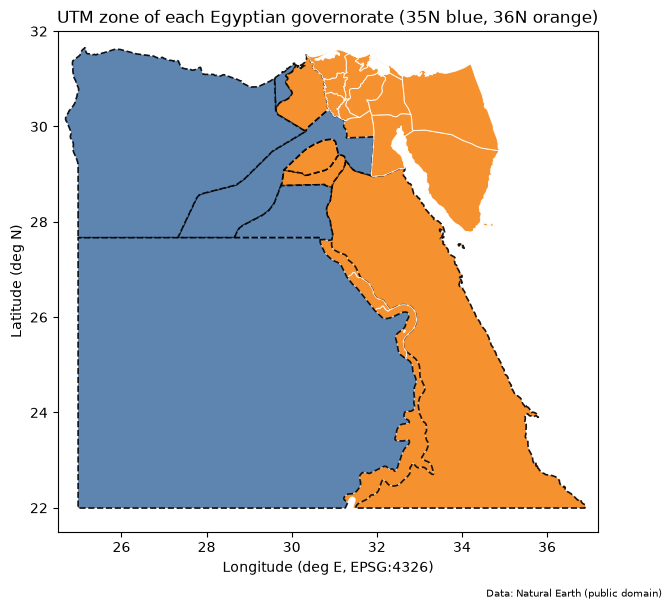

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import PathPatch
from matplotlib.path import Path as MPath

colors = {'35N': '#4c78a8', '36N': '#f58518'}
by_name = {r[0]: r for r in rows}
fig, ax = plt.subplots(figsize=(7, 6.5), dpi=100)
for f in data['features']:
    g = f['geometry']
    polys = [g['coordinates']] if g['type'] == 'Polygon' else g['coordinates']
    verts, codes = [], []
    for poly in polys:
        for ring in poly:
            verts += [tuple(c) for c in ring]
            codes += [MPath.MOVETO] + [MPath.LINETO] * (len(ring) - 2) + [MPath.CLOSEPOLY]
    r = by_name[f['properties']['name']]
    multi = ',' in r[3]
    ax.add_patch(PathPatch(MPath(verts, codes), facecolor=colors[r[1]], alpha=0.9,
                           edgecolor='black' if multi else 'white', linestyle='--' if multi else '-',
                           linewidth=1.2 if multi else 0.7))
ax.set_xlim(24.5, 37.2); ax.set_ylim(21.5, 32.0); ax.set_aspect(1.12)
ax.set_xlabel('Longitude (deg E, EPSG:4326)'); ax.set_ylabel('Latitude (deg N)')
ax.set_title('UTM zone of each Egyptian governorate (35N blue, 36N orange)')
fig.text(0.99, 0.01, 'Data: Natural Earth (public domain)', ha='right', fontsize=7)
plt.show()